Dataset shape: (569, 32)
=== Baseline Model Performance ===
                 Model  Accuracy  Precision   Recall  F1-Score  ROC-AUC
   Logistic Regression  0.964912   0.975000 0.928571  0.951220 0.996032
         Decision Tree  0.929825   0.904762 0.904762  0.904762 0.924603
         Random Forest  0.973684   1.000000 0.928571  0.962963 0.992890
Support Vector Machine  0.973684   1.000000 0.928571  0.962963 0.995370
  Neural Network (MLP)  0.964912   1.000000 0.904762  0.950000 0.993056


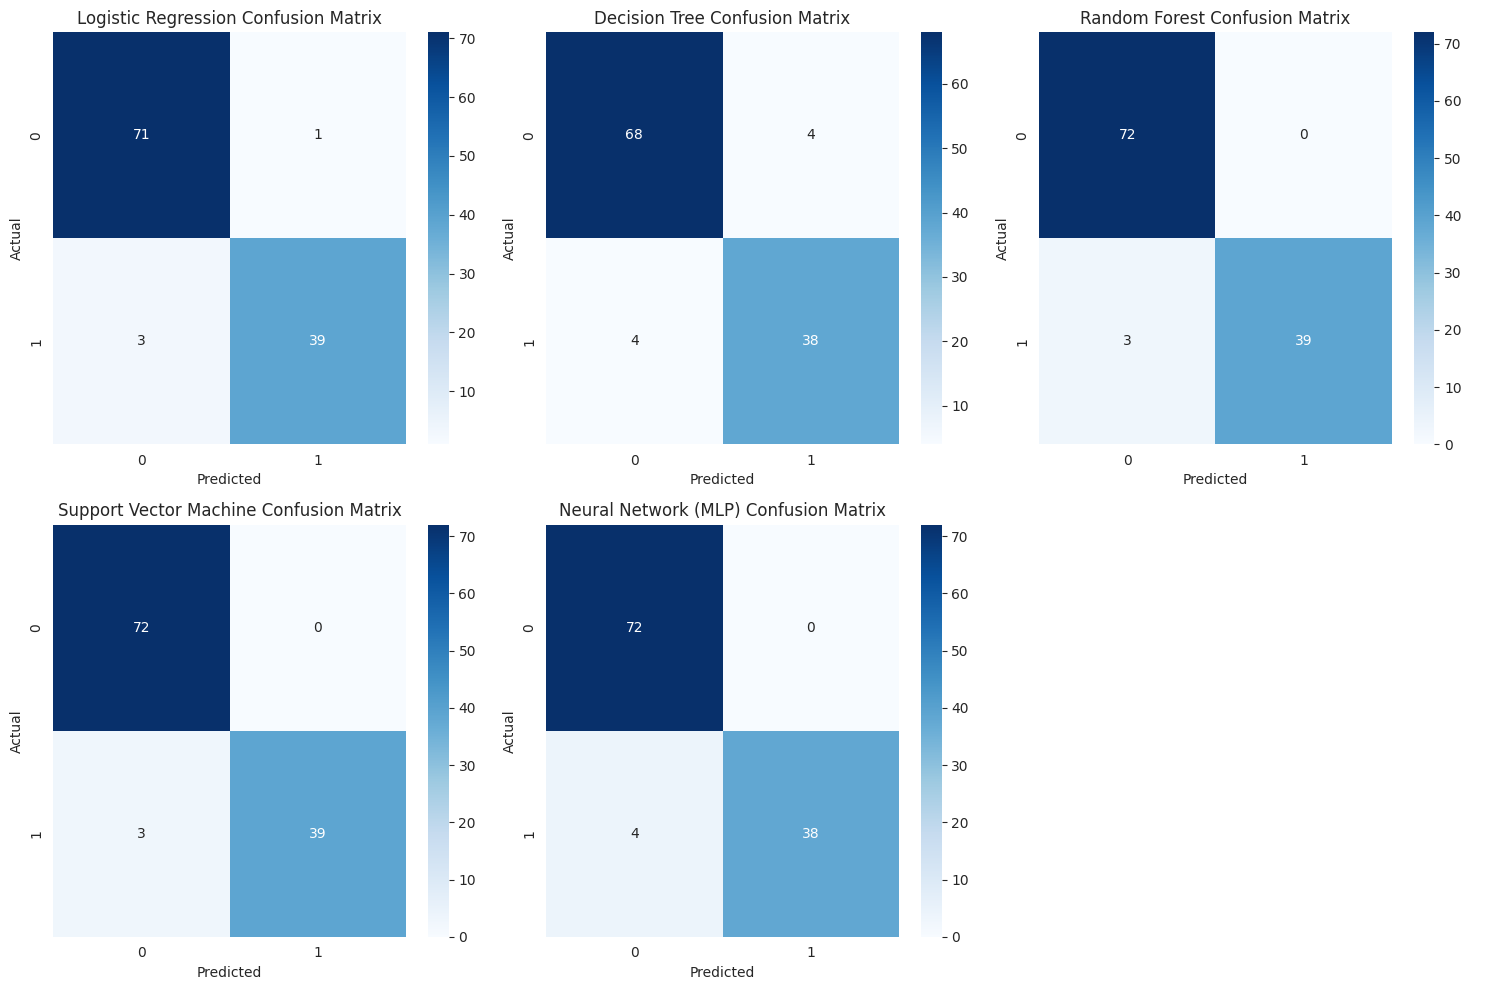

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptro


=== Optimized Parameters ===
Best SVM Parameters: {'C': 1, 'gamma': 'scale', 'kernel': 'rbf'}
Best Neural Network Parameters: {'activation': 'tanh', 'alpha': 0.0001, 'hidden_layer_sizes': (50,), 'solver': 'adam'}

=== Final Model Comparison (Before and After Tuning) ===
                     Model  Accuracy  Precision   Recall  F1-Score  ROC-AUC
       Logistic Regression  0.964912   0.975000 0.928571  0.951220 0.996032
             Decision Tree  0.929825   0.904762 0.904762  0.904762 0.924603
             Random Forest  0.973684   1.000000 0.928571  0.962963 0.992890
    Support Vector Machine  0.973684   1.000000 0.928571  0.962963 0.995370
      Neural Network (MLP)  0.964912   1.000000 0.904762  0.950000 0.993056
                 Tuned SVM  0.973684   1.000000 0.928571  0.962963 0.995370
Tuned Neural Network (MLP)  0.982456   1.000000 0.952381  0.975610 0.994378


/tmp/ipykernel_1957/13570040.py:185: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


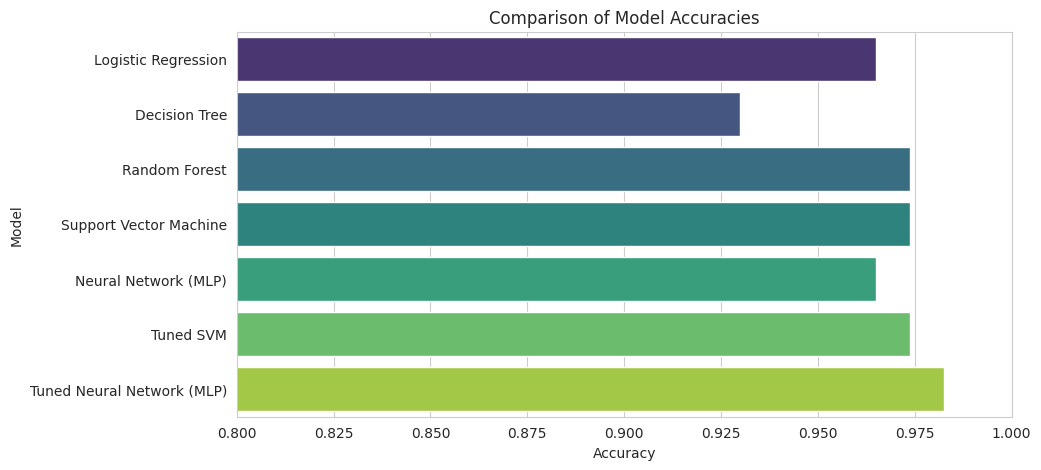

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler

# Make plots look cleaner
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
#%%
# Load the original UCI file.
# We use the direct URL so the notebook is reproducible without manual upload.

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/breast-cancer-wisconsin/wdbc.data"

# The original file has no header row, so we define column names manually.
columns = ["id", "diagnosis"] + [f"feature_{i}" for i in range(1, 31)]
df = pd.read_csv(url, header=None, names=columns)

print("Dataset shape:", df.shape)
df.head()

# ============================================================
# Essential Preprocessing for Modeling
# ============================================================
df = df.drop_duplicates().drop("id", axis=1)

le = LabelEncoder()
df["diagnosis"] = le.fit_transform(df["diagnosis"])

X = df.drop("diagnosis", axis=1)
y = df["diagnosis"]

scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)

# ============================================================
# Stage 2: Model Building and Evaluation
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split

# Import Machine Learning Classifiers
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

# 1. Train-Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)

# 2. Initialize Models
models = {
    "Logistic Regression": LogisticRegression(random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Support Vector Machine": SVC(probability=True, random_state=42),
    "Neural Network (MLP)": MLPClassifier(max_iter=500, random_state=42),
}

# 3. Train Models and Evaluate Metrics
results = []

for name, model in models.items():
  model.fit(X_train, y_train)
  y_pred = model.predict(X_test)
  y_proba = model.predict_proba(X_test)[:, 1]

  acc = accuracy_score(y_test, y_pred)
  prec = precision_score(y_test, y_pred)
  rec = recall_score(y_test, y_pred)
  f1 = f1_score(y_test, y_pred)
  auc = roc_auc_score(y_test, y_proba)

  results.append({
      "Model": name,
      "Accuracy": acc,
      "Precision": prec,
      "Recall": rec,
      "F1-Score": f1,
      "ROC-AUC": auc,
  })

df_results = pd.DataFrame(results)
print("=== Baseline Model Performance ===")
print(df_results.to_string(index=False))

# Plot Confusion Matrices
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for i, (name, model) in enumerate(models.items()):
  y_pred = model.predict(X_test)
  cm = confusion_matrix(y_test, y_pred)
  sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[i])
  axes[i].set_title(f"{name} Confusion Matrix")
  axes[i].set_xlabel("Predicted")
  axes[i].set_ylabel("Actual")

axes[-1].axis("off")
plt.tight_layout()
plt.show()

# ============================================================
# Stage 3: Model Optimization and Final Comparison
# ============================================================

from sklearn.model_selection import GridSearchCV

# Hyperparameter Tuning using GridSearchCV for SVM & Neural Network
param_grid_svm = {
    "C": [0.1, 1, 10],
    "kernel": ["linear", "rbf"],
    "gamma": ["scale", "auto"],
}

param_grid_mlp = {
    "hidden_layer_sizes": [(50,), (100,), (50, 50)],
    "activation": ["relu", "tanh"],
    "solver": ["adam", "sgd"],
    "alpha": [0.0001, 0.001],
}

# Tuning SVM
grid_svm = GridSearchCV(
    SVC(probability=True, random_state=42),
    param_grid_svm,
    cv=5,
    scoring="accuracy",
)
grid_svm.fit(X_train, y_train)
best_svm = grid_svm.best_estimator_

# Tuning MLP
grid_mlp = GridSearchCV(
    MLPClassifier(max_iter=500, random_state=42),
    param_grid_mlp,
    cv=5,
    scoring="accuracy",
)
grid_mlp.fit(X_train, y_train)
best_mlp = grid_mlp.best_estimator_

print("\n=== Optimized Parameters ===")
print("Best SVM Parameters:", grid_svm.best_params_)
print("Best Neural Network Parameters:", grid_mlp.best_params_)

# Evaluate Optimized Models
tuned_models = {"Tuned SVM": best_svm, "Tuned Neural Network (MLP)": best_mlp}

tuned_results = []
for name, model in tuned_models.items():
  y_pred = model.predict(X_test)
  y_proba = model.predict_proba(X_test)[:, 1]

  tuned_results.append({
      "Model": name,
      "Accuracy": accuracy_score(y_test, y_pred),
      "Precision": precision_score(y_test, y_pred),
      "Recall": recall_score(y_test, y_pred),
      "F1-Score": f1_score(y_test, y_pred),
      "ROC-AUC": roc_auc_score(y_test, y_proba),
  })

df_tuned_results = pd.DataFrame(tuned_results)
df_final_comparison = pd.concat([df_results, df_tuned_results], ignore_index=True)

print("\n=== Final Model Comparison (Before and After Tuning) ===")
print(df_final_comparison.to_string(index=False))

# Plot Final Accuracy Comparison
plt.figure(figsize=(10, 5))
sns.barplot(
    x="Accuracy", y="Model", data=df_final_comparison, palette="viridis"
)
plt.title("Comparison of Model Accuracies")
plt.xlim(0.8, 1.0)
plt.show()